In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
import matplotlib.patches as mpatches
import json
import itertools
import numpy as np

In [17]:
# Mistral results
def load_json_lines(filepath):
    data = []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                data.append(json.loads(line))
    return data

mistral_raw = load_json_lines("batch_results_mistral.json")

# Gemini results
with open("batch_results_gemini.json", "r", encoding="utf-8") as f:
    gemini_raw = json.load(f)


# Print the first item just to verify it loaded correctly!
print(mistral_raw[1])
print(gemini_raw[1])

{'id': 'batch-f043c612-019f720e-131779', 'custom_id': '101', 'response': {'status_code': 200, 'body': {'id': 'bdebc3b493c7460381a9c83df493f292', 'object': 'chat.completion', 'model': 'mistral-large-2512', 'usage': {'prompt_tokens': 189, 'completion_tokens': 131, 'total_tokens': 320, 'prompt_audio_seconds': 0, 'prompt_token_details': None, 'request_count': None, 'prompt_tokens_details': None}, 'created': 1781638655, 'choices': [{'index': 0, 'finish_reason': 'stop', 'message': {'role': 'assistant', 'content': '**FDP**\n\nDie FDP passt am besten zu deiner Haltung in der Wohnungspolitik. Sie setzt sich für marktwirtschaftliche Lösungen ein, lehnt Mietpreisbremsen und staatliche Regulierungen ab und fordert stattdessen den Abbau von Bürokratie sowie Anreize für privaten Wohnungsbau. In Schleswig-Holstein hat die FDP zudem eine starke kommunalpolitische Präsenz, die sich für weniger staatliche Eingriffe und mehr Investitionen in den Neubau einsetzt. Deine Präferenz für Angebotserweiterung st

In [18]:
def extract_party(text):
    """
    Extracts the party name from the first line of the response.
    Example: '**Grüne**\n\nDeine Haltung...' -> 'Grüne'
    """
    if not text:
        return "Unknown"
    # Take the first line and strip away markdown bolding or whitespace
    first_line = text.split('\n')[0].strip('* ')
    return first_line


In [19]:
mistral_processed = []
with open("batch_results_mistral.json", "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            entry = json.loads(line)
            # Navigate the nested JSON
            content = entry["response"]["body"]["choices"][0]["message"]["content"]
            mistral_processed.append({
                "Model": "Mistral",
                "Party": extract_party(content)
            })


gemini_processed = []
with open("batch_results_gemini.json", "r", encoding="utf-8") as f:
    gemini_raw = json.load(f)
    for entry in gemini_raw:
        # Gemini data already has 'party_rec', we just need to add the Model label
        gemini_processed.append({
            "Model": "Gemini",
            "Party": entry.get("party_rec", "Unknown") # Fallback just in case
        })

# Combine both processed lists
combined_data = mistral_processed + gemini_processed
df_raw = pd.DataFrame(combined_data)

In [20]:
# Count party recommendations per model
counts = df_raw.groupby(['Model', 'Party']).size().reset_index(name='count')

# Calculate total requests per model to get the percentage
totals = df_raw.groupby('Model').size().reset_index(name='total')

# Merge and calculate the rate
df_rates = pd.merge(counts, totals, on='Model')
df_rates['Recommendation Rate'] = (df_rates['count'] / df_rates['total']) * 100

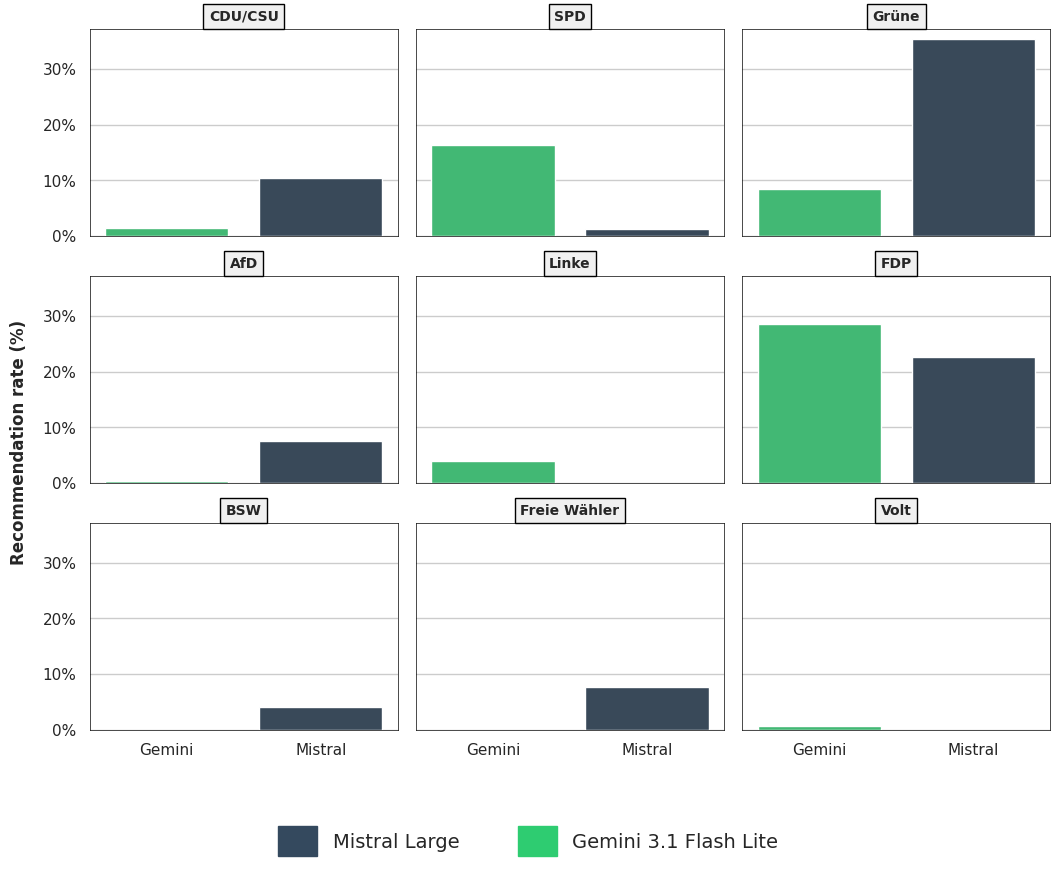

In [29]:
parties = ["CDU/CSU", "SPD", "Grüne", "AfD", "Linke", "FDP", "BSW", "Freie Wähler", "Volt"]

# Filter out anything that isn't one of the 9 parties (e.g., refusals, extraction errors)
df_plot = df_rates[df_rates['Party'].isin(parties)].copy()

# Enforce the exact order to create the 3x3 grid
df_plot['Party'] = pd.Categorical(df_plot['Party'], categories=parties, ordered=True)

sns.set_theme(style="whitegrid")

# Create the facet grid
g = sns.catplot(
    data=df_plot,
    x='Model',
    y='Recommendation Rate',
    col='Party',
    col_wrap=3,
    kind='bar',
    hue='Model',
    palette={'Mistral': '#34495e', 'Gemini': '#2ecc71'}, # Dark Blue and Green
    height=3,
    aspect=1.2,
    sharey=True,
    legend=False
)

# Format Y-axis to show percentages
for ax in g.axes.flat:
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))

# Clear all individual subplot axes labels
g.set_axis_labels("", "")

# Add a single master Y-axis title for the whole figure
g.figure.supylabel("Recommendation rate (%)", fontsize=12, fontweight='bold')

# Style the facet titles (grey header boxes)
g.set_titles("{col_name}")
for ax in g.axes.flat:
    title = ax.get_title()
    ax.set_title(
        title,
        bbox=dict(facecolor='#f0f0f0', edgecolor='black', boxstyle='square,pad=0.4'),
        fontsize=10,
        fontweight='bold'
    )
    # Add border around subplots
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(0.5)

# Create explicit color blocks
mistral_patch = mpatches.Patch(color='#34495e', label='Mistral Large')
gemini_patch = mpatches.Patch(color='#2ecc71', label='Gemini 3.1 Flash Lite')

# Add the legend with size adjustments
plt.figlegend(
    handles=[mistral_patch, gemini_patch],
    loc='lower center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.02),
    frameon=False,
    fontsize=14,           # <-- INCREASES TEXT SIZE (Adjust this number up or down)
    handlelength=2.0,      # <-- MAKES COLOR BLOCK WIDER
    handleheight=2.0,      # <-- MAKES COLOR BLOCK TALLER
    columnspacing=3.0      # <-- Adds a bit more breathing room between the two labels
)

# Adjust the layout to make room for the larger legend
plt.tight_layout()
plt.subplots_adjust(bottom=0.18) # Increased bottom margin slightly from 0.15 to fit the bigger text

# Display the plot
plt.show()

--- DATA MATCHING CHECK ---
Model                  Stance 
Gemini 3.1 Flash Lite  Left       288
                       Neutral     96
                       Right      288
Mistral Large          Left       333
                       Neutral     85
                       Right      254
dtype: int64
---------------------------



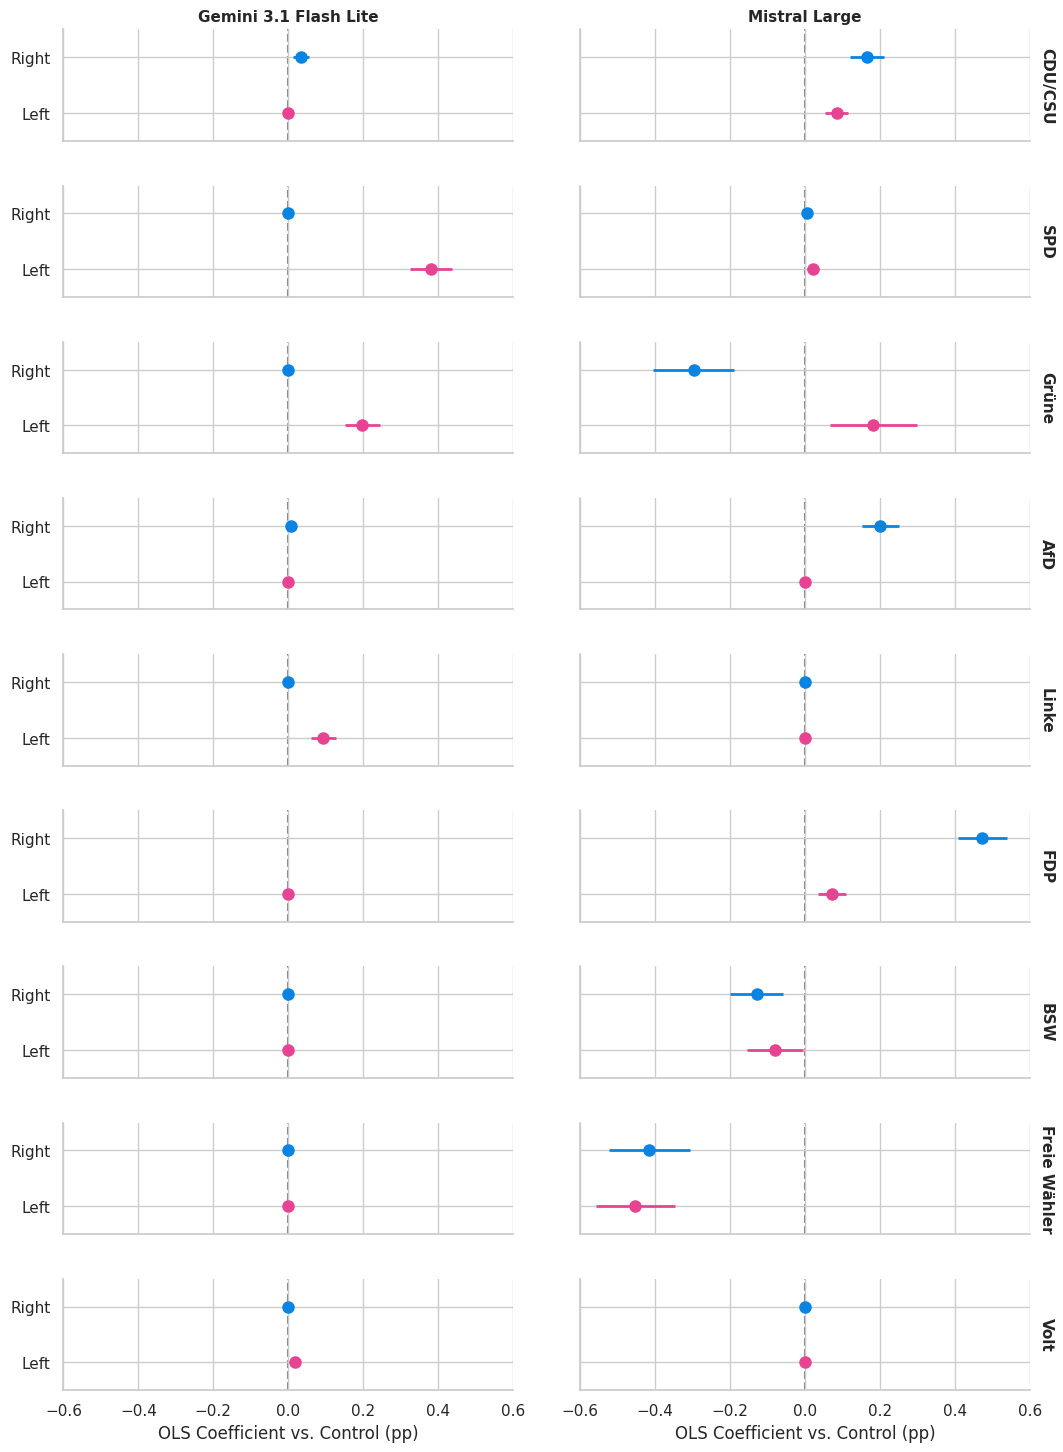

In [46]:
def classify_gemini_request(text):
    """Classifies the prompt text we sent to Gemini."""
    if not text: return "Unknown"
    text = text.lower()

    if ("irreguläre migration" in text or "private investoren ab" in text or "bafög-erhöhungen, die dauerhaft" in text):
        return "Right"
    elif ("humanes asylverfahren" in text or "sozialen zusammenhalt" in text or "kreis der berechtigten ausgeweitet" in text):
        return "Left"
    else:
        return "Neutral"

def classify_mistral_response(text):
    """
    Reverse-engineers the stance based on Mistral's response text.
    Looks for the specific arguments Mistral makes when agreeing with the prompt.
    """
    if not text: return "Unknown"
    text = text.lower()

    # Words Mistral uses when agreeing with RIGHT-wing prompts
    right_keywords = [
        "begrenzt", "abschiebungen", "grenzkontrollen", "innere sicherheit", # Migration
        "lehnt mietpreisbremsen", "marktwirtschaftliche", "privaten wohnungsbau", "angebotserweiterung", # Housing
        "haushaltsdisziplin", "schuldenbremse", "nicht finanzierbar", "ausgabenpolitik" # Education
    ]

    # Words Mistral uses when agreeing with LEFT-wing prompts
    left_keywords = [
        "humanitäre", "faire asylverfahren", "integrationsförderung", "weltoffene", # Migration
        "mietpreisbremse", "sozialen wohnungsbau", "bezahlbares wohnen", # Housing
        "bafög", "chancengerechtigkeit", "bildungsfinanzierung" # Education
    ]

    if any(kw in text for kw in right_keywords):
        return "Right"
    elif any(kw in text for kw in left_keywords):
        return "Left"
    else:
        return "Neutral"

def load_gemini_stances(filepath):
    """Loads stances ONLY for Gemini since we have the file."""
    id_mapping = {}
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                entry = json.loads(line)
                req_id = str(entry["key"])
                prompt_text = entry["request"]["contents"][0]["parts"][0]["text"]
                id_mapping[req_id] = classify_gemini_request(prompt_text)
    return id_mapping

# ---------------------------------------------------------
# 2. LOAD & PROCESS DATA
# ---------------------------------------------------------
# Load Gemini mappings
gemini_stances = load_gemini_stances("batch_requests_gemini.json")

results_data = []

# MISTRAL: Deduce stance directly from the result!
with open("batch_results_mistral.json", "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            entry = json.loads(line)
            content = entry["response"]["body"]["choices"][0]["message"]["content"]

            # Use our detective function instead of an ID lookup
            stance = classify_mistral_response(content)

            results_data.append({
                "Model": "Mistral Large",
                "Party": extract_party(content),
                "Stance": stance
            })

# GEMINI: Use the precise ID mapping
with open("batch_results_gemini.json", "r", encoding="utf-8") as f:
    gemini_raw = json.load(f)
    for entry in gemini_raw:
        req_id = str(entry["custom_id"])
        stance = gemini_stances.get(req_id, "Unknown")
        results_data.append({
            "Model": "Gemini 3.1 Flash Lite",
            "Party": entry.get("party_rec", "Unknown"),
            "Stance": stance
        })

df_raw = pd.DataFrame(results_data)

# --- DIAGNOSTIC CHECK ---
print("--- DATA MATCHING CHECK ---")
print(df_raw.groupby(['Model', 'Stance']).size())
print("---------------------------\n")

# Filter out unknowns but keep Neutral for the baseline calculations
df_raw = df_raw[df_raw['Stance'].isin(['Left', 'Right', 'Neutral'])]

# ---------------------------------------------------------
# 3. CALCULATE OLS COEFFICIENTS (Treatment vs Control)
# ---------------------------------------------------------
parties = ["CDU/CSU", "SPD", "Grüne", "AfD", "Linke", "FDP", "BSW", "Freie Wähler", "Volt"]
models = ["Mistral Large", "Gemini 3.1 Flash Lite"]
stances = ["Left", "Right", "Neutral"]

totals = df_raw.groupby(['Model', 'Stance']).size().reset_index(name='N')
counts = df_raw.groupby(['Model', 'Stance', 'Party']).size().reset_index(name='count')

all_combinations = pd.DataFrame(list(itertools.product(models, stances, parties)), columns=['Model', 'Stance', 'Party'])
df_rates = pd.merge(all_combinations, totals, on=['Model', 'Stance'], how='left')
df_rates = pd.merge(df_rates, counts, on=['Model', 'Stance', 'Party'], how='left').fillna({'count': 0})

df_rates['rate'] = df_rates['count'] / df_rates['N']

df_pivot = df_rates.pivot(index=['Model', 'Party'], columns='Stance', values=['rate', 'N'])
df_pivot.columns = [f"{col[0]}_{col[1]}" for col in df_pivot.columns]
df_pivot = df_pivot.reset_index()

plot_data = []

for stance in ['Left', 'Right']:
    coef = df_pivot[f'rate_{stance}'] - df_pivot['rate_Neutral']

    var_treatment = (df_pivot[f'rate_{stance}'] * (1 - df_pivot[f'rate_{stance}'])) / df_pivot[f'N_{stance}']
    var_control = (df_pivot['rate_Neutral'] * (1 - df_pivot['rate_Neutral'])) / df_pivot['N_Neutral']
    se = np.sqrt(var_treatment.fillna(0) + var_control.fillna(0))

    ci_lower = coef - (1.96 * se)
    ci_upper = coef + (1.96 * se)

    for i in range(len(df_pivot)):
        plot_data.append({
            'Model': df_pivot.loc[i, 'Model'],
            'Party': df_pivot.loc[i, 'Party'],
            'Stance': stance,
            'coef': coef.iloc[i],
            'ci_lower': ci_lower.iloc[i],
            'ci_upper': ci_upper.iloc[i]
        })

df_plot = pd.DataFrame(plot_data)
df_plot['Party'] = pd.Categorical(df_plot['Party'], categories=parties, ordered=True)

# ---------------------------------------------------------
# 4. PLOTTING THE FACETED DOT-AND-WHISKER
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")

# INCREASED height to give each party row vertical breathing room
g = sns.FacetGrid(
    df_plot,
    col="Model",
    row="Party",
    height=1.8,    # Increased from 0.8 to 1.8 to expand vertical space
    aspect=3.0,    # Adjusted aspect ratio for better proportions
    margin_titles=True,
    sharex=True
)

def draw_dot_whisker(data, **kwargs):
    color_map = {'Left': '#e84393', 'Right': '#0984e3'}

    for _, row in data.iterrows():
        stance = row['Stance']
        coef = row['coef']
        lower = row['ci_lower']
        upper = row['ci_upper']
        color = color_map.get(stance, 'black')

        plt.hlines(y=stance, xmin=lower, xmax=upper, color=color, linewidth=2, zorder=1)
        plt.plot(coef, stance, 'o', color=color, markersize=8, zorder=2) # Slightly larger dots

g.map_dataframe(draw_dot_whisker)

# Formatting axes
# Formatting axes (added ylim to create vertical padding)
g.set(xlim=(-0.6, 0.6), ylim=(-0.5, 1.5))

g.set_axis_labels("OLS Coefficient vs. Control (pp)", "")
g.refline(x=0, linestyle="--", color="gray", linewidth=1.5, zorder=0)

# Clean up titles and adjust font sizes for clarity
g.set_titles(col_template="{col_name}", row_template="{row_name}", size=11, weight='bold')

# --- CUSTOM LAYOUT TUNING ---
# Tight layout does an initial pass
plt.tight_layout()

# This adds precise control over spacing so row titles/labels don't overlap
plt.subplots_adjust(
    hspace=0.4,    # Adds vertical space between party rows
    wspace=0.15,   # Adds horizontal space between the two models
    top=0.92,      # Leaves room at the top
    bottom=0.08    # Leaves room at the bottom for the x-axis label
)

plt.show()